# Sleep Staging — 05: Gradient Boosting Models

**Objetivo:** comparar XGBoost, LightGBM y CatBoost sobre las mismas features de NB3 y usando exactamente el mismo holdout por sujeto definido en NB4.

**Criterio principal:** Macro-F1. Los tres modelos usan pesos de clase balanceados calculados únicamente sobre el conjunto de entrenamiento de cada fold.

Se usan configuraciones fijas y simples, sin búsqueda exhaustiva de hiperparámetros. Los resultados se guardan por fold para poder reanudar una ejecución interrumpida.


---
## 0. Setup


In [2]:
import os

N_THREADS = min(4, os.cpu_count() or 1)

for variable in [
    "OMP_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "MKL_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[variable] = str(N_THREADS)

from pathlib import Path
import gc
import json
import time
import warnings

import joblib
import numpy as np
import pandas as pd
import psutil

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import display, Image

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
)
from sklearn.model_selection import GroupKFold
from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

DATA_DIR = Path("../data/processed")
FIGURES_DIR = Path("../reports/figures")
MODELS_DIR = Path("../models")
RESULTS_DIR = Path("../reports/results")

FEATURES_PATH = DATA_DIR / "features_full.parquet"

BASELINE_SPLIT_PATH = RESULTS_DIR / "baseline_subject_split.json"
BASELINE_CV_PATH = RESULTS_DIR / "baseline_feature_reduction_cv.csv"
BASELINE_HOLDOUT_PATH = RESULTS_DIR / "baseline_holdout_metrics.json"

FOLD_RESULTS_PATH = RESULTS_DIR / "boosting_fold_results.csv"
CV_RESULTS_PATH = RESULTS_DIR / "boosting_cv_results.csv"
HOLDOUT_PATH = RESULTS_DIR / "boosting_holdout_metrics.json"
PREDICTIONS_PATH = RESULTS_DIR / "boosting_holdout_predictions.parquet"
MODEL_PATH = MODELS_DIR / "boosting_best_model.joblib"

for directory in (FIGURES_DIR, MODELS_DIR, RESULTS_DIR):
    directory.mkdir(parents=True, exist_ok=True)

BOOSTING_ARTIFACTS = [
    FOLD_RESULTS_PATH,
    CV_RESULTS_PATH,
    HOLDOUT_PATH,
    PREDICTIONS_PATH,
    MODEL_PATH,
]

if FEATURES_PATH.exists() and BASELINE_SPLIT_PATH.exists():
    source_mtime = max(
        FEATURES_PATH.stat().st_mtime,
        BASELINE_SPLIT_PATH.stat().st_mtime,
    )

    stale = any(
        path.exists() and path.stat().st_mtime < source_mtime
        for path in BOOSTING_ARTIFACTS
    )

    if stale:
        print("NB3/NB4 fueron actualizadas: se eliminan artefactos previos de NB5.")
        for path in BOOSTING_ARTIFACTS:
            if path.exists():
                path.unlink()

RANDOM_STATE = 42
N_SPLITS = 3
N_CLASSES = 5

STAGE_MAP = {0: "W", 1: "N1", 2: "N2", 3: "N3", 4: "REM"}
STAGE_ORDER = list(STAGE_MAP)
STAGE_NAMES = [STAGE_MAP[idx] for idx in STAGE_ORDER]

print("Setup completado.")
print(f"Threads por modelo: {N_THREADS}")


Setup completado.
Threads por modelo: 4


---
## 1. Carga y validación del dataset


In [3]:
if not FEATURES_PATH.exists():
    raise FileNotFoundError(f"No se encontró: {FEATURES_PATH.resolve()}")

features_df = pd.read_parquet(FEATURES_PATH)

METADATA_COLS = [
    "epoch_global",
    "epoch_in_subject",
    "source_epoch_index",
    "recording_onset_s",
    "label",
    "subject",
    "qc_status",
    "qc_reason",
    "review_mask",
]

missing_metadata = [
    col for col in METADATA_COLS
    if col not in features_df.columns
]

if missing_metadata:
    raise ValueError(
        "Faltan columnas de metadata esperadas desde NB3: "
        + ", ".join(missing_metadata)
    )

FEATURE_COLS = [
    col for col in features_df.columns
    if col not in METADATA_COLS
]

X = features_df[FEATURE_COLS].astype(np.float32)
y = features_df["label"].astype(np.int8)
groups = features_df["subject"].astype(str)

assert len(X) == len(y) == len(groups)
assert set(y.unique()).issubset(STAGE_MAP)
assert not (set(METADATA_COLS) & set(FEATURE_COLS))

print(f"Dataset:   {features_df.shape}")
print(f"Features:  {len(FEATURE_COLS)}")
print(f"Epochs:    {len(features_df)}")
print(f"Sujetos:   {groups.nunique()}")


Dataset:   (135471, 195)
Features:  186
Epochs:    135471
Sujetos:   149


---
## 2. Mismo holdout por sujeto que en la notebook 04

Se reutiliza directamente `baseline_subject_split.json`. De esta forma, boosting y baseline se evalúan sobre exactamente los mismos sujetos.


In [4]:
if not BASELINE_SPLIT_PATH.exists():
    raise FileNotFoundError(
        "No se encontró baseline_subject_split.json. "
        "Ejecutá primero la NB4 final."
    )

if BASELINE_SPLIT_PATH.stat().st_mtime < FEATURES_PATH.stat().st_mtime:
    raise RuntimeError(
        "El split de NB4 es anterior a features_full.parquet. "
        "Ejecutá nuevamente la NB4 final antes de continuar."
    )

with open(BASELINE_SPLIT_PATH, "r", encoding="utf-8") as file:
    split_info = json.load(file)

train_subjects = set(map(str, split_info["train_subjects"]))
test_subjects = set(map(str, split_info["test_subjects"]))

assert train_subjects.isdisjoint(test_subjects)

dataset_subjects = set(groups.unique())
split_subjects = train_subjects | test_subjects

if dataset_subjects != split_subjects:
    missing = sorted(dataset_subjects - split_subjects)
    extra = sorted(split_subjects - dataset_subjects)

    raise ValueError(
        "El split de NB4 no coincide con los sujetos de NB3.\n"
        f"Sujetos sin asignar: {missing}\n"
        f"Sujetos extra en split: {extra}"
    )

train_mask = groups.isin(train_subjects).to_numpy()
test_mask = groups.isin(test_subjects).to_numpy()

train_idx = np.flatnonzero(train_mask)
test_idx = np.flatnonzero(test_mask)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

assert set(groups_train.unique()) == train_subjects
assert set(groups_test.unique()) == test_subjects
assert train_subjects.isdisjoint(test_subjects)

del X
gc.collect()

print(f"Train epochs:    {len(X_train)}")
print(f"Test epochs:     {len(X_test)}")
print(f"Train subjects:  {len(train_subjects)}")
print(f"Test subjects:   {len(test_subjects)}")
print(f"RAM kernel:      {psutil.Process(os.getpid()).memory_info().rss / 1024**3:.2f} GB")


Train epochs:    108839
Test epochs:     26632
Train subjects:  119
Test subjects:   30
RAM kernel:      0.55 GB


---
## 3. Resultados de referencia del baseline


In [5]:
baseline_cv = pd.read_csv(BASELINE_CV_PATH) if BASELINE_CV_PATH.exists() else None
baseline_holdout = None

if baseline_cv is not None:
    display(baseline_cv.sort_values("f1_macro_mean", ascending=False).round(4))

if BASELINE_HOLDOUT_PATH.exists():
    with open(BASELINE_HOLDOUT_PATH, "r", encoding="utf-8") as f:
        baseline_holdout = json.load(f)
    display(pd.Series(baseline_holdout).to_frame("value"))


,experiment,fit_time_mean,fit_time_std,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std
0,Random Forest | All features,131.1848,0.2354,0.7357,0.0051,0.7043,0.0066,0.7024,0.0068
1,SGD | All features,25.0004,0.4046,0.7246,0.0047,0.7057,0.0069,0.6928,0.0039
2,Random Forest | ANOVA top 50,67.1049,1.4217,0.7062,0.0028,0.6726,0.0009,0.6685,0.0015
3,SGD | ANOVA top 50,7.0590,0.2402,0.7044,0.0046,0.6673,0.0032,0.6591,0.0022
4,SGD | Mutual information top 50,86.9572,0.2066,0.6973,0.0044,0.6614,0.0036,0.6523,0.0020
5,Dummy | All features,0.0963,0.0127,0.3610,0.0083,0.2000,0.0000,0.1061,0.0018


,value
experiment,Random Forest | All features
accuracy,0.734342
balanced_accuracy,0.70448
f1_macro,0.701136
n_train_epochs,108839
n_test_epochs,26632
n_train_subjects,119
n_test_subjects,30


---
## 4. Configuración de modelos


In [6]:
models = {
    "XGBoost": XGBClassifier(
        objective="multi:softprob",
        num_class=N_CLASSES,
        n_estimators=250,
        learning_rate=0.05,
        max_depth=6,
        min_child_weight=2,
        subsample=0.85,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        tree_method="hist",
        device="cpu",
        eval_metric="mlogloss",
        n_jobs=N_THREADS,
        random_state=RANDOM_STATE,
    ),

    "LightGBM": LGBMClassifier(
        objective="multiclass",
        num_class=N_CLASSES,
        n_estimators=250,
        learning_rate=0.05,
        num_leaves=31,
        min_child_samples=30,
        subsample=0.85,
        subsample_freq=1,
        colsample_bytree=0.85,
        reg_alpha=0.05,
        reg_lambda=1.0,
        n_jobs=N_THREADS,
        random_state=RANDOM_STATE,
        verbosity=-1,
    ),

    "CatBoost": CatBoostClassifier(
        loss_function="MultiClass",
        iterations=250,
        learning_rate=0.05,
        depth=7,
        l2_leaf_reg=3.0,
        random_seed=RANDOM_STATE,
        thread_count=N_THREADS,
        verbose=False,
        allow_writing_files=False,
        task_type="CPU",
    ),
}

for name in models:
    print("-", name)


- XGBoost
- LightGBM
- CatBoost


---
## 5. Funciones de evaluación


In [7]:
def evaluate_fold(model, X_fit, y_fit, X_valid, y_valid):
    # Pesos calculados únicamente con las clases del train del fold.
    sample_weight = compute_sample_weight(
        class_weight="balanced",
        y=y_fit,
    )

    start = time.perf_counter()

    model.fit(
        X_fit,
        y_fit,
        sample_weight=sample_weight,
    )

    pred = np.asarray(
        model.predict(X_valid)
    ).reshape(-1)

    return {
        "accuracy": accuracy_score(y_valid, pred),
        "balanced_accuracy": balanced_accuracy_score(y_valid, pred),
        "f1_macro": f1_score(y_valid, pred, average="macro"),
        "fit_time": time.perf_counter() - start,
    }


def summarize(results):
    rows = []

    for name, group in results.groupby("model"):
        row = {"model": name}

        for metric in [
            "accuracy",
            "balanced_accuracy",
            "f1_macro",
            "fit_time",
        ]:
            row[f"{metric}_mean"] = group[metric].mean()
            row[f"{metric}_std"] = group[metric].std(ddof=0)

        rows.append(row)

    return (
        pd.DataFrame(rows)
        .sort_values("f1_macro_mean", ascending=False)
        .reset_index(drop=True)
    )


---
## 6. Cross-validation recuperable


In [8]:
if FOLD_RESULTS_PATH.exists():
    fold_results = pd.read_csv(FOLD_RESULTS_PATH)
    completed = set(zip(fold_results["model"], fold_results["fold"]))
    print(f"Folds recuperados: {len(completed)}")
else:
    fold_results = pd.DataFrame()
    completed = set()

cv = GroupKFold(n_splits=N_SPLITS)

for model_name, base_model in models.items():
    print(f"\n{'='*60}\n{model_name}\n{'='*60}")

    for fold, (fit_idx, valid_idx) in enumerate(
        cv.split(X_train, y_train, groups_train), start=1
    ):
        if (model_name, fold) in completed:
            print(f"Fold {fold}: ya evaluado")
            continue

        print(
            f"Fold {fold}/{N_SPLITS} | "
            f"RAM: {psutil.Process(os.getpid()).memory_info().rss / 1024**3:.2f} GB"
        )

        model = clone(base_model)
        result = evaluate_fold(
            model,
            X_train.iloc[fit_idx], y_train.iloc[fit_idx],
            X_train.iloc[valid_idx], y_train.iloc[valid_idx],
        )
        result.update({
            "model": model_name,
            "fold": fold,
            "n_train": len(fit_idx),
            "n_valid": len(valid_idx),
        })

        fold_results = pd.concat([fold_results, pd.DataFrame([result])], ignore_index=True)
        fold_results.to_csv(FOLD_RESULTS_PATH, index=False)

        print(
            f"Macro-F1: {result['f1_macro']:.4f} | "
            f"Balanced acc: {result['balanced_accuracy']:.4f} | "
            f"Tiempo: {result['fit_time']:.1f}s"
        )

        del model
        gc.collect()

cv_results = summarize(fold_results)
cv_results.to_csv(CV_RESULTS_PATH, index=False)
display(cv_results.round(4))



XGBoost
Fold 1/3 | RAM: 0.56 GB
Macro-F1: 0.7238 | Balanced acc: 0.7352 | Tiempo: 44.8s
Fold 2/3 | RAM: 0.67 GB
Macro-F1: 0.7230 | Balanced acc: 0.7361 | Tiempo: 43.6s
Fold 3/3 | RAM: 0.67 GB
Macro-F1: 0.7163 | Balanced acc: 0.7298 | Tiempo: 44.1s

LightGBM
Fold 1/3 | RAM: 0.67 GB
Macro-F1: 0.7250 | Balanced acc: 0.7345 | Tiempo: 27.6s
Fold 2/3 | RAM: 0.68 GB
Macro-F1: 0.7264 | Balanced acc: 0.7393 | Tiempo: 27.2s
Fold 3/3 | RAM: 0.68 GB
Macro-F1: 0.7237 | Balanced acc: 0.7363 | Tiempo: 27.9s

CatBoost
Fold 1/3 | RAM: 0.68 GB
Macro-F1: 0.7118 | Balanced acc: 0.7254 | Tiempo: 188.4s
Fold 2/3 | RAM: 0.69 GB
Macro-F1: 0.7106 | Balanced acc: 0.7281 | Tiempo: 136.2s
Fold 3/3 | RAM: 0.69 GB
Macro-F1: 0.7094 | Balanced acc: 0.7251 | Tiempo: 136.1s


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,fit_time_mean,fit_time_std
0,LightGBM,0.7427,0.0020,0.7367,0.0020,0.7250,0.0011,27.5595,0.2988
1,XGBoost,0.7387,0.0033,0.7337,0.0028,0.7210,0.0034,44.1803,0.5073
2,CatBoost,0.7258,0.0017,0.7262,0.0013,0.7106,0.0010,153.5702,24.6135


---
## 7. Comparación contra el baseline


In [9]:
comparison_rows=[]

if baseline_cv is not None:
    ref = baseline_cv[baseline_cv["experiment"] == "SGD | All features"]
    if not ref.empty:
        r=ref.iloc[0]
        comparison_rows.append({
            "model":"SGD baseline",
            "accuracy_mean":r["accuracy_mean"],
            "balanced_accuracy_mean":r["balanced_accuracy_mean"],
            "f1_macro_mean":r["f1_macro_mean"],
            "fit_time_mean":r["fit_time_mean"],
        })

for _, r in cv_results.iterrows():
    comparison_rows.append({
        "model":r["model"],
        "accuracy_mean":r["accuracy_mean"],
        "balanced_accuracy_mean":r["balanced_accuracy_mean"],
        "f1_macro_mean":r["f1_macro_mean"],
        "fit_time_mean":r["fit_time_mean"],
    })

comparison_df = pd.DataFrame(comparison_rows).sort_values("f1_macro_mean", ascending=False)
display(comparison_df.round(4))


,model,accuracy_mean,balanced_accuracy_mean,f1_macro_mean,fit_time_mean
1,LightGBM,0.7427,0.7367,0.7250,27.5595
2,XGBoost,0.7387,0.7337,0.7210,44.1803
3,CatBoost,0.7258,0.7262,0.7106,153.5702
0,SGD baseline,0.7246,0.7057,0.6928,25.0004


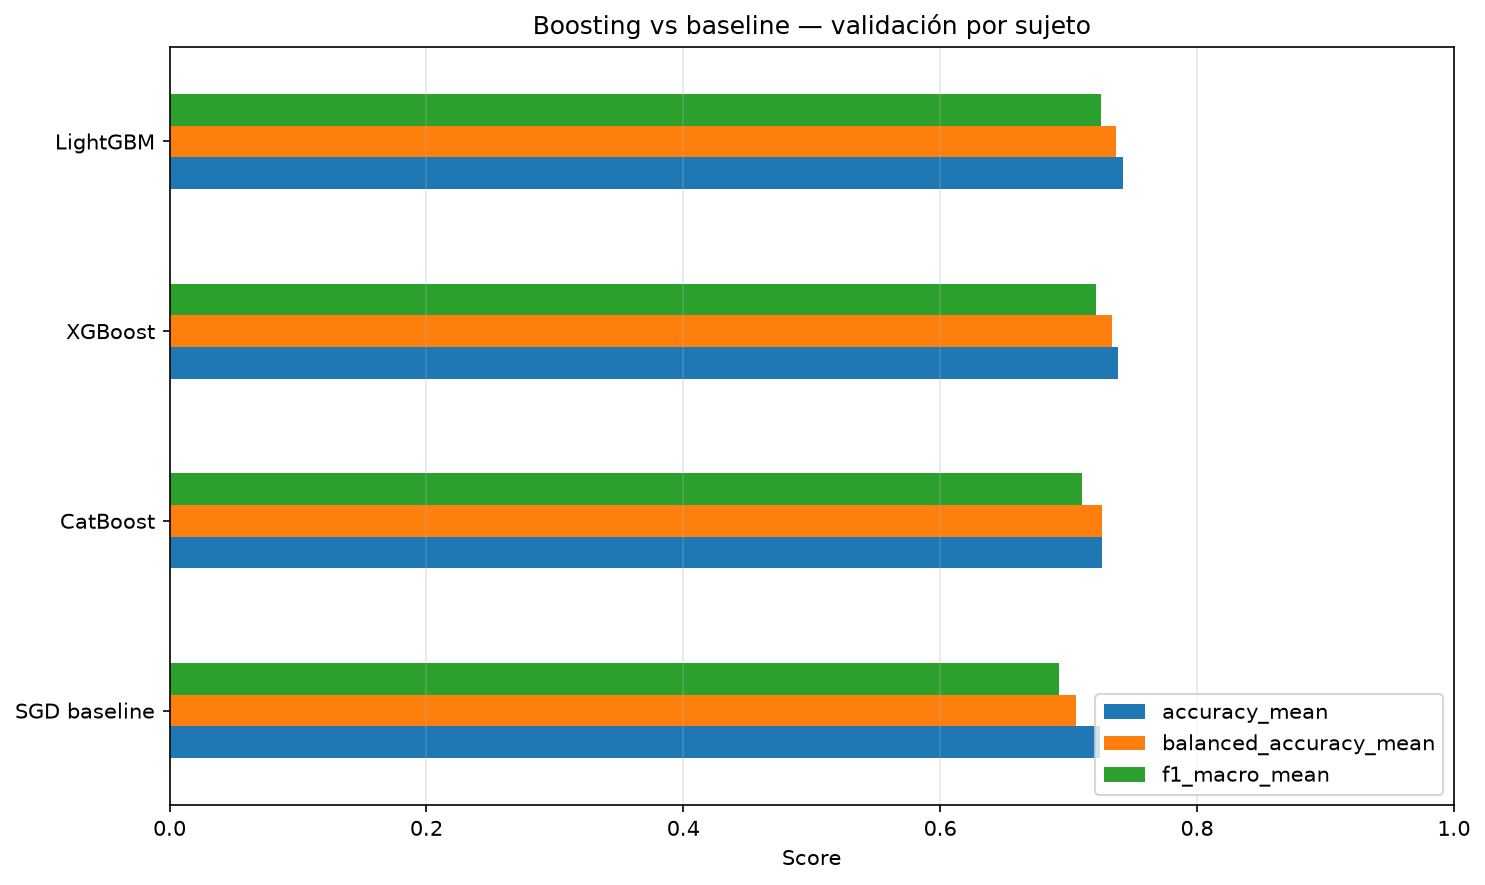

In [10]:
PLOT_PATH = FIGURES_DIR / "boosting_vs_baseline_cv.png"
plot_df = comparison_df.set_index("model")[[
    "accuracy_mean", "balanced_accuracy_mean", "f1_macro_mean"
]].sort_values("f1_macro_mean")

fig, ax = plt.subplots(figsize=(10, 6))
plot_df.plot(kind="barh", ax=ax)
ax.set_title("Boosting vs baseline — validación por sujeto")
ax.set_xlabel("Score")
ax.set_ylabel("")
ax.set_xlim(0, 1)
ax.grid(axis="x", alpha=0.3)
fig.tight_layout()
fig.savefig(PLOT_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(PLOT_PATH), width=950))


---
## 8. Selección y entrenamiento final

El modelo final se selecciona únicamente por el mayor **Macro-F1 medio de cross-validation**. El holdout permanece sin utilizar hasta esta etapa.


In [11]:
best_row = cv_results.loc[
    cv_results["f1_macro_mean"].idxmax()
]

best_model_name = best_row["model"]
best_model = clone(models[best_model_name])

print("Modelo seleccionado:", best_model_name)
display(
    cv_results.sort_values(
        "f1_macro_mean",
        ascending=False,
    ).round(4)
)

final_sample_weight = compute_sample_weight(
    class_weight="balanced",
    y=y_train,
)

best_model.fit(
    X_train,
    y_train,
    sample_weight=final_sample_weight,
)

y_pred = np.asarray(
    best_model.predict(X_test)
).reshape(-1)

holdout_metrics = {
    "model": best_model_name,
    "accuracy": float(
        accuracy_score(y_test, y_pred)
    ),
    "balanced_accuracy": float(
        balanced_accuracy_score(y_test, y_pred)
    ),
    "f1_macro": float(
        f1_score(y_test, y_pred, average="macro")
    ),
    "n_train_epochs": int(len(X_train)),
    "n_test_epochs": int(len(X_test)),
    "n_train_subjects": int(len(train_subjects)),
    "n_test_subjects": int(len(test_subjects)),
    "class_weighting": "balanced_sample_weight",
}

display(
    pd.Series(holdout_metrics).to_frame("value")
)

print(
    classification_report(
        y_test,
        y_pred,
        labels=STAGE_ORDER,
        target_names=STAGE_NAMES,
        digits=4,
        zero_division=0,
    )
)


Modelo seleccionado: LightGBM


,model,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,f1_macro_mean,f1_macro_std,fit_time_mean,fit_time_std
0,LightGBM,0.7427,0.0020,0.7367,0.0020,0.7250,0.0011,27.5595,0.2988
1,XGBoost,0.7387,0.0033,0.7337,0.0028,0.7210,0.0034,44.1803,0.5073
2,CatBoost,0.7258,0.0017,0.7262,0.0013,0.7106,0.0010,153.5702,24.6135


,value
model,LightGBM
accuracy,0.740951
balanced_accuracy,0.732959
f1_macro,0.721854
n_train_epochs,108839
n_test_epochs,26632
n_train_subjects,119
n_test_subjects,30
class_weighting,balanced_sample_weight


              precision    recall  f1-score   support

           W     0.7989    0.7774    0.7880      4354
          N1     0.3863    0.4906    0.4323      3043
          N2     0.8170    0.7071    0.7581     10169
          N3     0.7853    0.8508    0.8168      5014
         REM     0.7908    0.8388    0.8141      4052

    accuracy                         0.7410     26632
   macro avg     0.7157    0.7330    0.7219     26632
weighted avg     0.7549    0.7410    0.7453     26632



### 8.1 Matriz de confusión


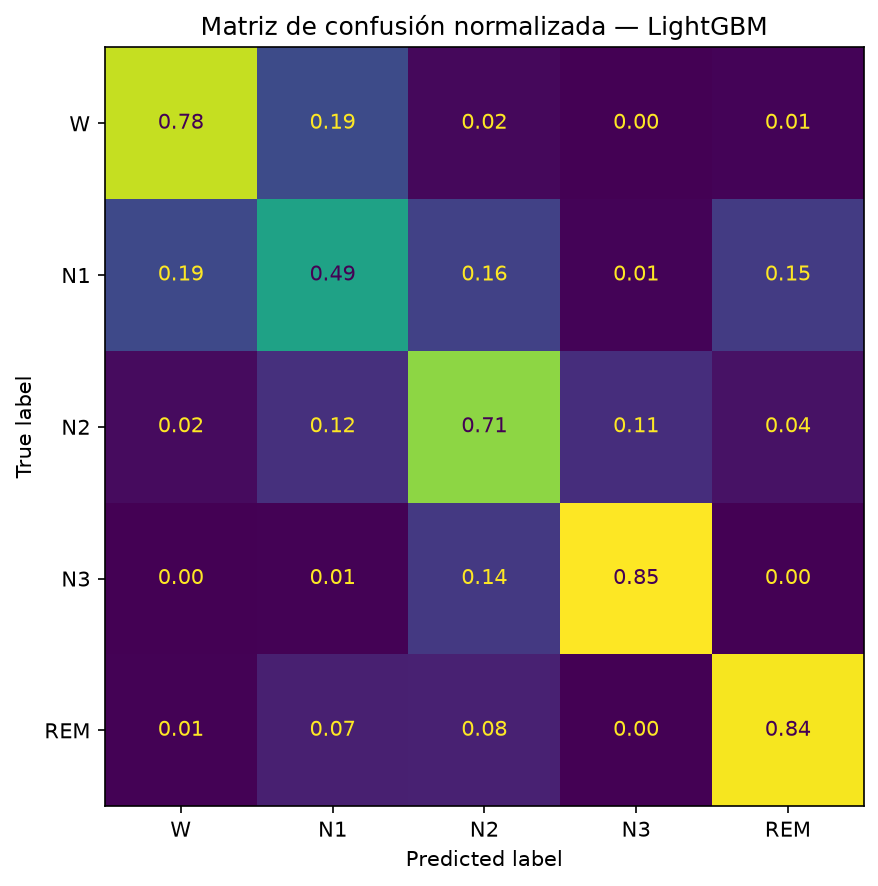

In [12]:
CM_PATH = FIGURES_DIR / "boosting_holdout_confusion_matrix.png"
cm = confusion_matrix(y_test, y_pred, labels=STAGE_ORDER, normalize="true")
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=STAGE_NAMES).plot(
    ax=ax, values_format=".2f", colorbar=False
)
ax.set_title(f"Matriz de confusión normalizada — {best_model_name}")
fig.tight_layout()
fig.savefig(CM_PATH, dpi=150, bbox_inches="tight")
plt.close(fig)
display(Image(filename=str(CM_PATH), width=700))


---
## 9. Importancia de features


In [13]:
importance_df = None
if hasattr(best_model, "feature_importances_"):
    importance_df = pd.DataFrame({
        "feature": FEATURE_COLS,
        "importance": np.asarray(best_model.feature_importances_, dtype=float),
    }).sort_values("importance", ascending=False).reset_index(drop=True)
    display(importance_df.head(20))


,feature,importance
0,EEG O2-M1__ratio_theta_alpha,829.0
1,EMG chin__power_20_35,688.0
2,EEG C3-M2__ratio_sigma_beta,657.0
3,EMG chin__zcr,649.0
4,EMG chin__perm_entropy,637.0
5,EEG F4-M1__perm_entropy,534.0
6,EEG C3-M2__zcr,500.0
7,EEG O2-M1__perm_entropy,498.0
8,EEG F4-M1__ratio_theta_alpha,489.0
9,EOG E1-M2__alpha_abs,482.0


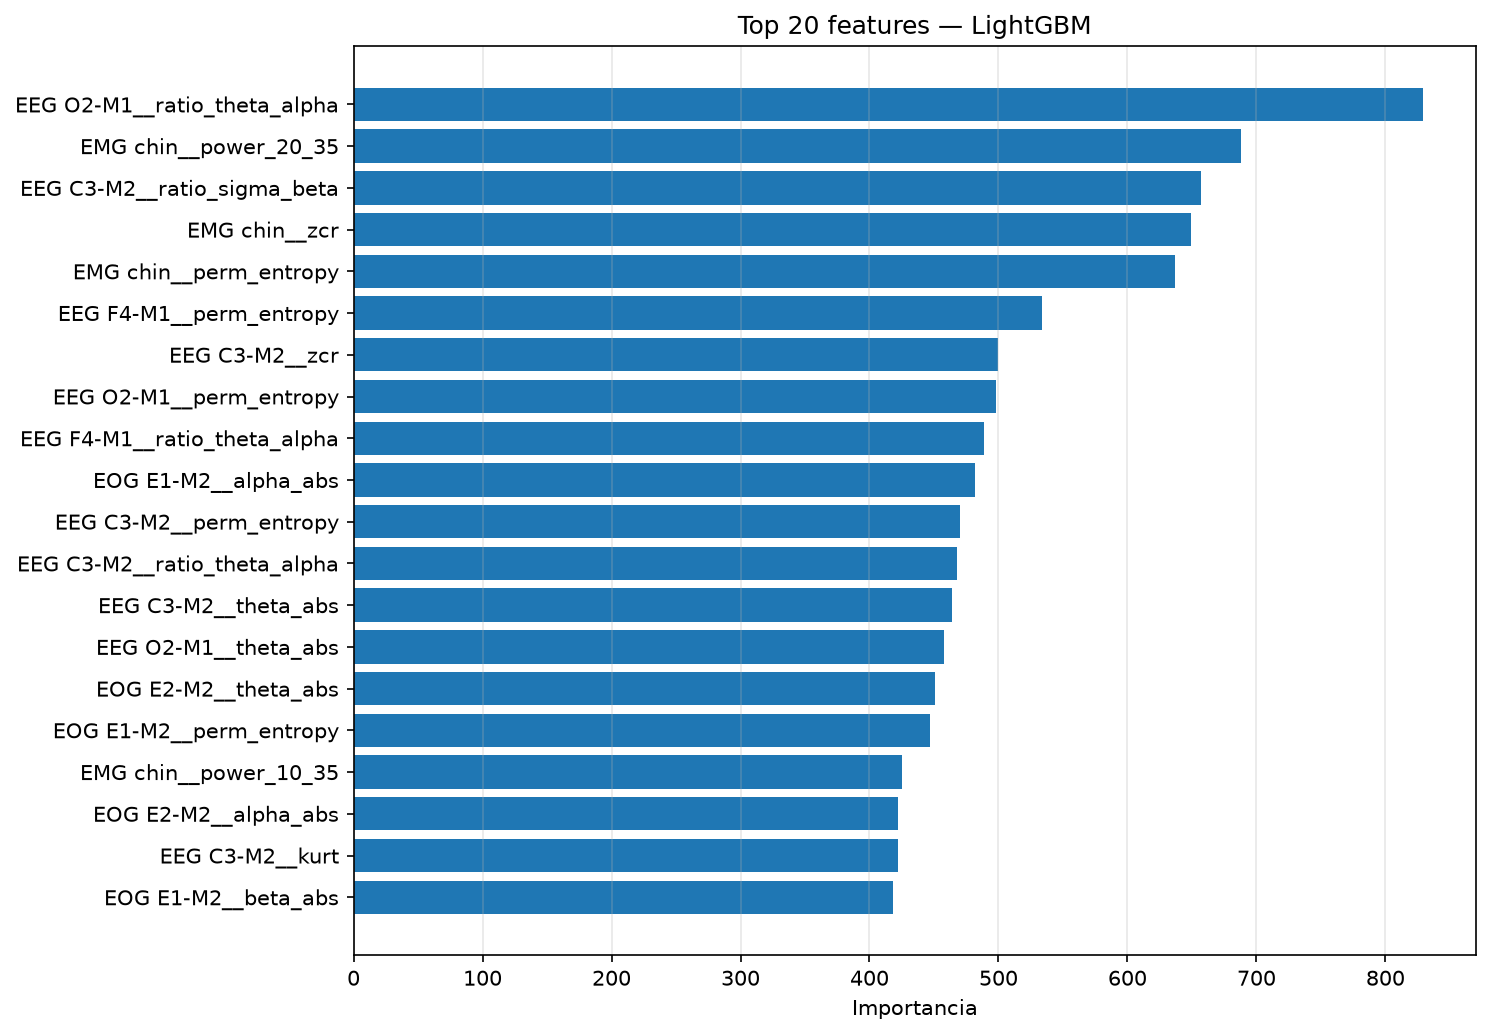

In [14]:
if importance_df is not None:
    IMP_PATH = FIGURES_DIR / "boosting_feature_importance.png"
    top = importance_df.head(20).sort_values("importance")
    fig, ax = plt.subplots(figsize=(10, 7))
    ax.barh(top["feature"], top["importance"])
    ax.set_title(f"Top 20 features — {best_model_name}")
    ax.set_xlabel("Importancia")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(IMP_PATH, dpi=150, bbox_inches="tight")
    plt.close(fig)
    display(Image(filename=str(IMP_PATH), width=950))


---
## 10. Guardado de artefactos


In [15]:
joblib.dump(
    {
        "model": best_model,
        "feature_names": FEATURE_COLS,
        "stage_map": STAGE_MAP,
        "model_name": best_model_name,
        "class_weighting": "balanced_sample_weight",
    },
    MODEL_PATH,
)

predictions_df = (
    features_df
    .iloc[test_idx][METADATA_COLS]
    .copy()
)

predictions_df["y_true"] = y_test.to_numpy()
predictions_df["y_pred"] = y_pred.astype(np.int8)

predictions_df.to_parquet(
    PREDICTIONS_PATH,
    index=False,
)

with open(HOLDOUT_PATH, "w", encoding="utf-8") as file:
    json.dump(
        holdout_metrics,
        file,
        indent=2,
        ensure_ascii=False,
    )

print("Modelo:", MODEL_PATH.resolve())
print("Predicciones:", PREDICTIONS_PATH.resolve())
print("Métricas:", HOLDOUT_PATH.resolve())


Modelo: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\models\boosting_best_model.joblib
Predicciones: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\boosting_holdout_predictions.parquet
Métricas: C:\Users\tolot\Documents\UBA\2026\TP\sleep-staging-tp\reports\results\boosting_holdout_metrics.json


---
## 11. Checklist final


In [16]:
checks = {
    "Sin solapamiento de sujetos": (
        train_subjects.isdisjoint(test_subjects)
    ),
    "Mismo split que NB4": (
        set(groups_train.unique()) == train_subjects
        and set(groups_test.unique()) == test_subjects
    ),
    "Metadata excluida de features": not bool(
        set(METADATA_COLS) & set(FEATURE_COLS)
    ),
    "Resultados por fold guardados": FOLD_RESULTS_PATH.exists(),
    "Resumen de CV guardado": CV_RESULTS_PATH.exists(),
    "Modelo guardado": MODEL_PATH.exists(),
    "Predicciones guardadas": PREDICTIONS_PATH.exists(),
    "Métricas guardadas": HOLDOUT_PATH.exists(),
    "Predicciones alineadas": len(y_pred) == len(y_test),
}

print("=" * 72)
print("CHECKLIST — GRADIENT BOOSTING")
print("=" * 72)

for label, passed in checks.items():
    print(f"{'✅' if passed else '❌'}  {label}")

print("\nResumen:")
print(f"  modelo:                {best_model_name}")
print(f"  holdout accuracy:      {holdout_metrics['accuracy']:.4f}")
print(f"  balanced accuracy:     {holdout_metrics['balanced_accuracy']:.4f}")
print(f"  holdout Macro-F1:      {holdout_metrics['f1_macro']:.4f}")


CHECKLIST — GRADIENT BOOSTING
✅  Sin solapamiento de sujetos
✅  Mismo split que NB4
✅  Metadata excluida de features
✅  Resultados por fold guardados
✅  Resumen de CV guardado
✅  Modelo guardado
✅  Predicciones guardadas
✅  Métricas guardadas
✅  Predicciones alineadas

Resumen:
  modelo:                LightGBM
  holdout accuracy:      0.7410
  balanced accuracy:     0.7330
  holdout Macro-F1:      0.7219
